# What Netflix Chose to Stream: An Exploratory Analysis of 8,800 Titles

**Author:** Pham Hong Hieu (Haven) · **Data:** `netflix_titles.csv`, the Netflix catalogue as of 2021 (8,807 titles)

## The question

Imagine joining a content-strategy team and being handed the full catalogue on day one. Before anyone talks about
what to license next, the team needs a shared, factual picture of what is already there:

1. Is the catalogue built around films or series, and how long are they?
2. Who is the catalogue made for (audience ratings)?
3. When did Netflix add most of its titles, and is the mix shifting?
4. Which genres, directors and countries dominate?
5. What themes recur in title descriptions?

The notebook follows four steps: **prepare → clean → engineer features → visualise and interpret**.
Each chart is saved to `reports/figures/` so the README can tell the same story.

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA = Path("../data/netflix_titles.csv")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")
NETFLIX_RED, NETFLIX_BLACK, SLATE = "#E50914", "#221F1F", "#4C78A8"


def save(fig, name):
    """Save a chart for the README alongside showing it in the notebook."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(DATA)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 8,807 | Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Data overview

Before cleaning, check the structure: column types, how many distinct values each column holds, and where data
are missing.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [4]:
df.nunique().sort_values(ascending=False)

show_id         8807
title           8807
description     8775
cast            7692
director        4528
date_added      1767
country          748
listed_in        514
duration         220
release_year      74
rating            17
type               2
dtype: int64

## 3. Data cleaning

Three issues need attention:

- **Duplicates.** Check for fully repeated rows.
- **A data-entry error in `duration`.** Three stand-up specials have their running time (for example `74 min`)
  recorded in the `rating` column. Fixing these first avoids deleting otherwise valid titles.
- **Missing values.** `director`, `cast` and `country` are missing for many titles, but the rest of each record is
  still useful, so they become `"Unknown"`. `date_added` drives the time analysis, so the 10 titles without a valid
  date are dropped.

The principle: investigate a missing value before deleting it, repair it when possible, and remove a row only when
the analysis cannot use it.

In [5]:
print("Fully duplicated rows:", df.duplicated().sum())

missing = df.isna().sum()
pd.DataFrame({
    "missing": missing,
    "missing_pct": (missing / len(df) * 100).round(2),
}).query("missing > 0").sort_values("missing", ascending=False)

Fully duplicated rows:

 0


,missing,missing_pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


In [6]:
# Titles whose running time was entered in the rating column
df.loc[df["duration"].isna(), ["show_id", "type", "title", "rating", "duration"]]

,show_id,type,title,rating,duration
5541,s5542,Movie,Louis C.K. 2017,74 min,NaN
5794,s5795,Movie,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,66 min,NaN


In [7]:
misplaced = df["duration"].isna() & df["rating"].astype(str).str.match(r"^\d+\s+min$", na=False)
df.loc[misplaced, "duration"] = df.loc[misplaced, "rating"]
df.loc[misplaced, "rating"] = np.nan
print("Rows with the running time moved back to `duration`:", int(misplaced.sum()))

for column in ["director", "cast", "country", "rating"]:
    df[column] = df[column].fillna("Unknown")

df["date_added"] = pd.to_datetime(df["date_added"].astype(str).str.strip(), errors="coerce")
df = df.dropna(subset=["date_added"]).copy()

remaining = df.isna().sum()
print("Missing values after cleaning:", int(remaining.sum()))
print("Final shape:", df.shape)

Rows with the running time moved back to `duration`:

 3
Missing values after cleaning: 0
Final shape: (8797, 12)


## 4. Feature engineering

- `added_year`, `added_month`: when the title arrived on Netflix (not when it was released).
- `duration_num`: the number inside `duration`, read as **minutes** for movies and **seasons** for TV shows.
- `description_length`: characters in the synopsis.

In [8]:
df["added_year"] = df["date_added"].dt.year
df["added_month"] = df["date_added"].dt.month
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")
df["description_length"] = df["description"].str.len()

movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]
df[["title", "type", "added_year", "added_month", "duration", "duration_num"]].head()

,title,type,added_year,added_month,duration,duration_num
0,Dick Johnson Is Dead,Movie,2021,9,90 min,90
1,Blood & Water,TV Show,2021,9,2 Seasons,2
2,Ganglands,TV Show,2021,9,1 Season,1
3,Jailbirds New Orleans,TV Show,2021,9,1 Season,1
4,Kota Factory,TV Show,2021,9,2 Seasons,2


## 5. Analysis

### 5.1 Films or series?

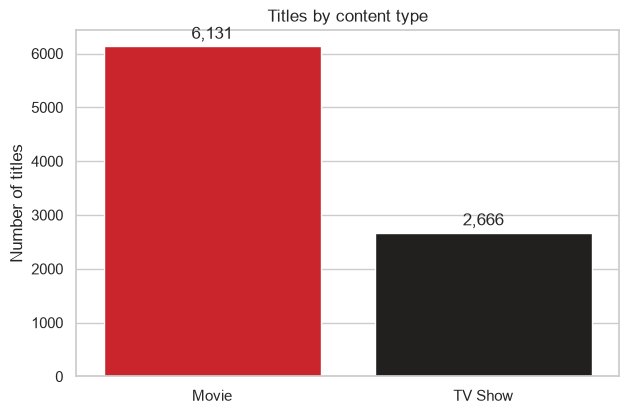

,type,titles,share_pct
0,Movie,6131,69.7
1,TV Show,2666,30.3


In [9]:
type_mix = df["type"].value_counts().rename_axis("type").reset_index(name="titles")
type_mix["share_pct"] = (type_mix["titles"] / type_mix["titles"].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=type_mix, x="type", y="titles", hue="type", legend=False,
            palette={"Movie": NETFLIX_RED, "TV Show": NETFLIX_BLACK}, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.set(title="Titles by content type", xlabel="", ylabel="Number of titles")
save(fig, "01_titles_by_type")
plt.show()
type_mix

Movies make up roughly **seven in ten** titles. Netflix's catalogue in this period was still primarily a film library.

### 5.2 How long are they?

Movies are measured in minutes and series in seasons, so each gets its own distribution.

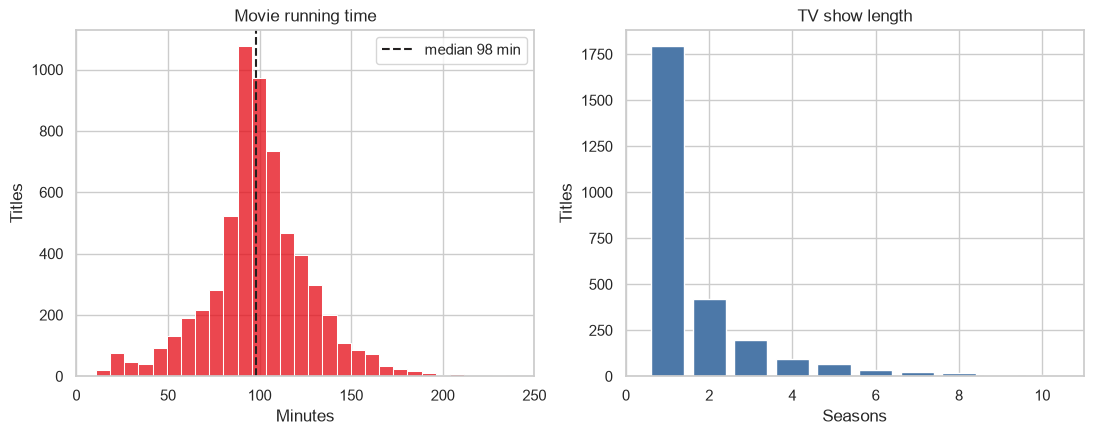

Median movie: 98 minutes
TV shows with a single season: 67.3%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(movies["duration_num"], bins=40, color=NETFLIX_RED, ax=axes[0])
axes[0].axvline(movies["duration_num"].median(), color=NETFLIX_BLACK, linestyle="--",
                label=f"median {movies['duration_num'].median():.0f} min")
axes[0].set(title="Movie running time", xlabel="Minutes", ylabel="Titles", xlim=(0, 250))
axes[0].legend()

season_counts = shows["duration_num"].value_counts().sort_index()
axes[1].bar(season_counts.index, season_counts.values, color=SLATE)
axes[1].set(title="TV show length", xlabel="Seasons", ylabel="Titles", xlim=(0, 11))
save(fig, "02_duration_distribution")
plt.show()

one_season_share = (shows["duration_num"] == 1).mean() * 100
print(f"Median movie: {movies['duration_num'].median():.0f} minutes")
print(f"TV shows with a single season: {one_season_share:.1f}%")

Movies cluster around a standard feature length, while about two thirds of the series never got past a first season.
This fits a catalogue that tests many series and renews only a small share of them.

### 5.3 Who is the catalogue for?

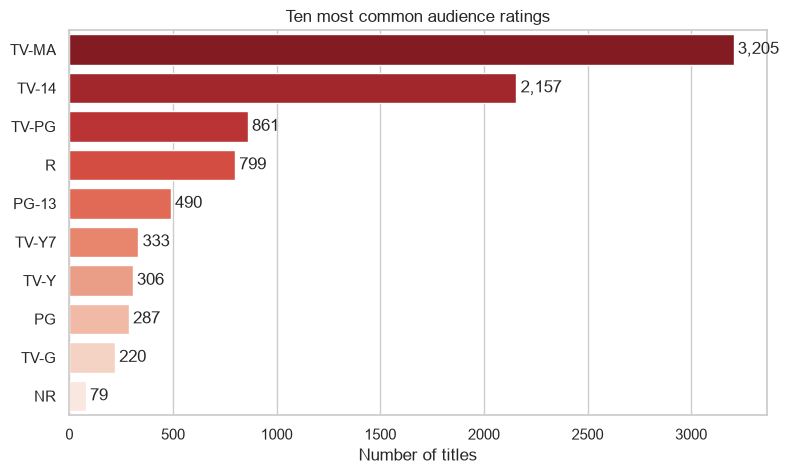

Adult-only ratings (TV-MA, R, NC-17): 45.5% of titles


In [11]:
ratings = df["rating"].value_counts().head(10).rename_axis("rating").reset_index(name="titles")
mature_share = df["rating"].isin(["TV-MA", "R", "NC-17"]).mean() * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ratings, x="titles", y="rating", hue="rating", legend=False, palette="Reds_r", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.set(title="Ten most common audience ratings", xlabel="Number of titles", ylabel="")
save(fig, "03_ratings")
plt.show()
print(f"Adult-only ratings (TV-MA, R, NC-17): {mature_share:.1f}% of titles")
df["rating"].value_counts().rename_axis("rating").reset_index(name="titles").to_csv(TABLE_DIR / "ratings.csv", index=False)

**TV-MA** (mature audiences) is the single largest rating, and adult-only ratings together account for more than
four in ten titles. The catalogue is aimed first at adults, with children's ratings (TV-Y, TV-Y7, TV-G) a smaller,
separate shelf.

### 5.4 When did the catalogue grow, and did the mix change?

`added_year` is the year a title arrived on Netflix, not its release year.

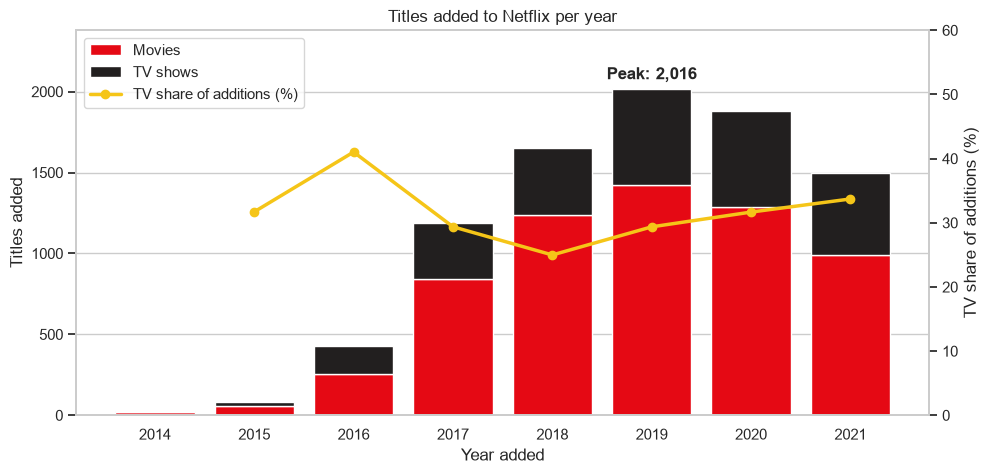

In [12]:
by_year = df.groupby(["added_year", "type"]).size().unstack(fill_value=0)
by_year["total"] = by_year.sum(axis=1)
by_year["tv_share_pct"] = by_year["TV Show"] / by_year["total"] * 100
peak_year = int(by_year["total"].idxmax())
peak_count = int(by_year["total"].max())

plot_years = by_year.loc[by_year.index >= 2014]  # fewer than 25 titles a year before 2014
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(plot_years.index, plot_years["Movie"], color=NETFLIX_RED, label="Movies")
ax1.bar(plot_years.index, plot_years["TV Show"], bottom=plot_years["Movie"], color=NETFLIX_BLACK, label="TV shows")
ax1.set(title="Titles added to Netflix per year", xlabel="Year added", ylabel="Titles added",
        ylim=(0, peak_count * 1.18))
ax1.set_xticks(plot_years.index)
ax1.text(peak_year, peak_count * 1.03, f"Peak: {peak_count:,}", ha="center", fontweight="bold")
ax1.grid(axis="x", visible=False)
ax2 = ax1.twinx()
recent = by_year.loc[by_year.index >= 2015]
ax2.plot(recent.index, recent["tv_share_pct"], color="#F5C518", marker="o", linewidth=2.5,
         label="TV share of additions (%)")
ax2.set_ylabel("TV share of additions (%)")
ax2.set_ylim(0, 60)
ax2.grid(False)
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(handles, labels, loc="upper left")
save(fig, "04_additions_by_year")
plt.show()

by_year.round(1).to_csv(TABLE_DIR / "titles_added_by_year.csv", index_label="year_added")

Additions accelerated sharply after 2015 and peaked in **2019**. The mix moved in two phases. During the 2017–2018
expansion, films made up most of the new additions, and the TV share fell to 25%. From 2019 onward the TV share rose
every year, to about a third of additions in 2021. The library was turning back toward series even though films still
dominated the total. The 2021 figure covers only January to September, because the data were collected in
September 2021.

### 5.5 Seasonality: which months receive new titles?

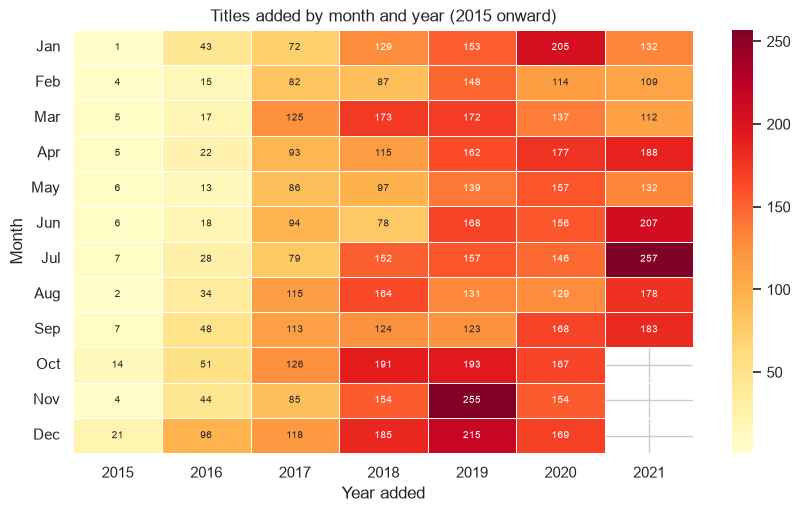

Busiest month overall: 7 (827 titles)
Quietest month overall: 2 (563 titles)


In [13]:
heat = df.pivot_table(values="show_id", index="added_month", columns="added_year", aggfunc="count")
heat = heat.reindex(range(1, 13)).loc[:, 2015:]

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.4, annot=True, fmt=".0f", annot_kws={"size": 7}, ax=ax)
ax.set(title="Titles added by month and year (2015 onward)", xlabel="Year added", ylabel="Month")
ax.set_yticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=0)
save(fig, "05_monthly_heatmap")
plt.show()

month_totals = df.groupby("added_month").size()
print("Busiest month overall:", month_totals.idxmax(), f"({month_totals.max():,} titles)")
print("Quietest month overall:", month_totals.idxmin(), f"({month_totals.min():,} titles)")

No single month dominates every year. Across all years, **July** and **December** received the most titles, and
**February** and **May** the fewest. This pattern fits the summer and year-end holiday viewing peaks. The spread
between the busiest and quietest months is under 50%, though, so additions are spread across the year rather than
batched into a few months.

### 5.6 Which genres dominate?

`listed_in` can hold several genres per title (for example `Dramas, International Movies`), so it is split and
exploded before counting.

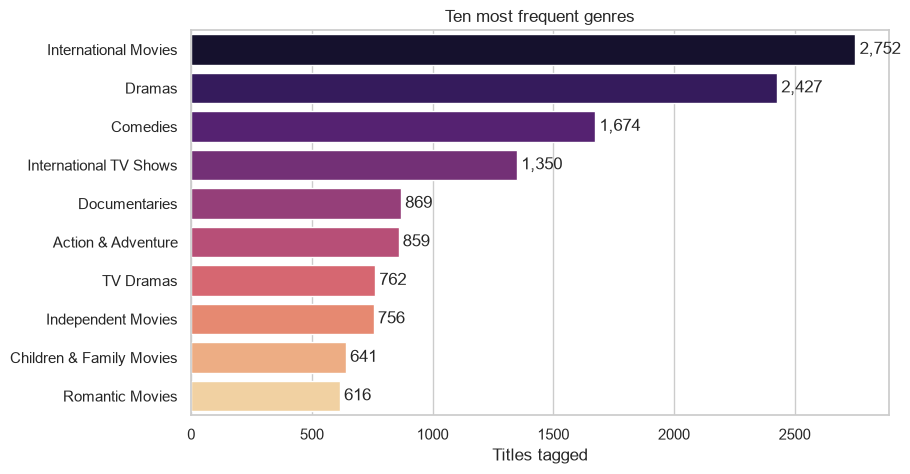

Titles tagged as International: 46.6%


In [14]:
genres = df["listed_in"].str.split(", ").explode()
top_genres = genres.value_counts().head(10).rename_axis("genre").reset_index(name="titles")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_genres, x="titles", y="genre", hue="genre", legend=False, palette="magma", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.set(title="Ten most frequent genres", xlabel="Titles tagged", ylabel="")
save(fig, "06_top_genres")
plt.show()

international_share = df["listed_in"].str.contains("International").mean() * 100
genres.value_counts().rename_axis("genre").reset_index(name="titles").to_csv(TABLE_DIR / "genres.csv", index=False)
print(f"Titles tagged as International: {international_share:.1f}%")

**International Movies** is the most frequent tag, and nearly half of all titles carry an *International* label.
Local-language content is a pillar of the catalogue, not a niche.

### 5.7 Which countries supply the catalogue?

Co-productions list several countries, so the field is split before counting. `Unknown` is excluded.

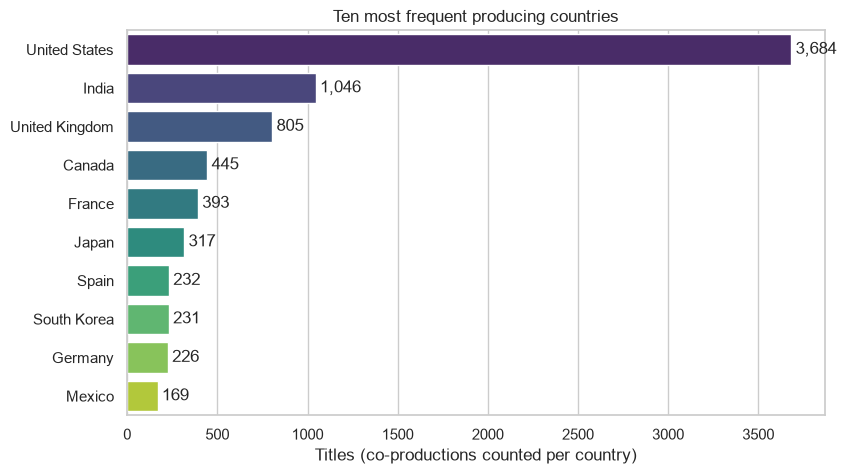

In [15]:
countries = df.loc[df["country"] != "Unknown", "country"].str.split(", ").explode().str.strip(", ")
top_countries = countries.value_counts().head(10).rename_axis("country").reset_index(name="titles")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_countries, x="titles", y="country", hue="country", legend=False, palette="viridis", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.set(title="Ten most frequent producing countries", xlabel="Titles (co-productions counted per country)", ylabel="")
save(fig, "07_top_countries")
plt.show()
top_countries.to_csv(TABLE_DIR / "top_countries.csv", index=False)

The **United States** leads by a wide margin, followed by **India** and the **United Kingdom**. India's second place
is consistent with the strength of the International tag above.

### 5.8 Which directors appear most often?

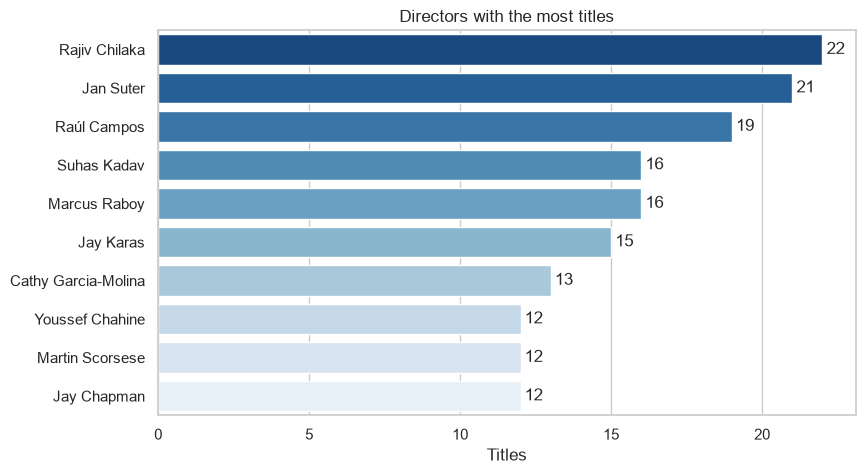

In [16]:
directors = df.loc[df["director"] != "Unknown", "director"].str.split(", ").explode()
top_directors = directors.value_counts().head(10).rename_axis("director").reset_index(name="titles")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_directors, x="titles", y="director", hue="director", legend=False, palette="Blues_r", ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set(title="Directors with the most titles", xlabel="Titles", ylabel="")
save(fig, "08_top_directors")
plt.show()

The top of the list mixes children's animation (Rajiv Chilaka, Suhas Kadav), stand-up comedy specials (Jan Suter,
Raúl Campos, Marcus Raboy, Jay Karas) and auteur cinema (Martin Scorsese, Youssef Chahine). The most prolific names are those
working in formats that are cheap to produce in volume, such as comedy specials and episodic animation.

### 5.9 What do the descriptions talk about?

A word cloud gives a quick visual impression. The frequency table beside it is the more precise measure.

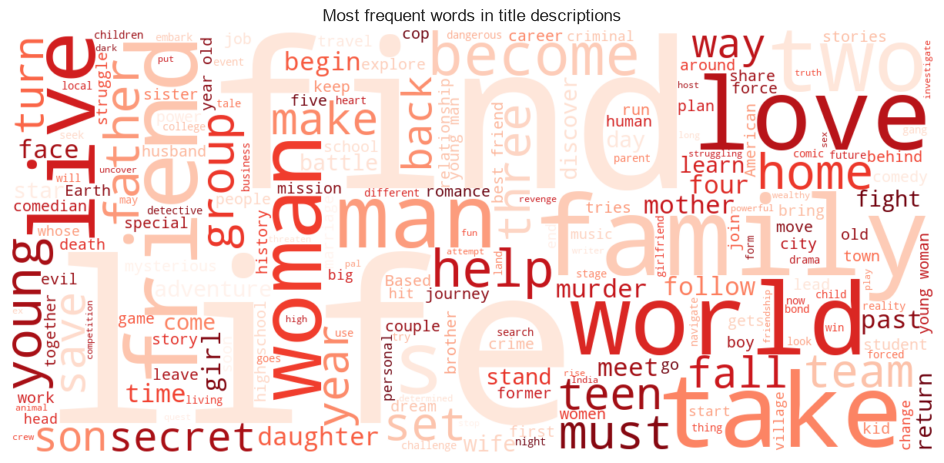

,mentions
description,
life,831
young,729
family,589
world,527
man,514
two,505
love,502
woman,463
friends,439


In [17]:
from wordcloud import WordCloud, STOPWORDS

stopwords = set(STOPWORDS) | {"film", "movie", "one", "new", "series", "documentary", "show"}
text = " ".join(df["description"].dropna().astype(str))
cloud = WordCloud(width=1200, height=550, background_color="white", colormap="Reds",
                  stopwords=stopwords, random_state=42).generate(text)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Most frequent words in title descriptions")
save(fig, "09_description_wordcloud")
plt.show()

words = (df["description"].str.lower().str.findall(r"[a-z']+").explode())
top_words = words[~words.isin(stopwords) & (words.str.len() > 2)].value_counts().head(15)
top_words.rename("mentions").to_frame()

Descriptions return again and again to **life, young, family, world, love** and **friends**. These are
relationship-driven, coming-of-age storylines, consistent with a drama-heavy genre mix. A word cloud is only
exploratory. Testing how themes relate to genres would need n-grams or topic modelling.

## 6. Key findings

In [18]:
findings = {
    "Movies share of titles": f"{(df['type'] == 'Movie').mean() * 100:.1f}%",
    "Median movie length": f"{movies['duration_num'].median():.0f} minutes",
    "TV shows with one season": f"{one_season_share:.1f}%",
    "Most common rating": f"{df['rating'].value_counts().idxmax()} ({df['rating'].value_counts().max():,} titles)",
    "Adult-only ratings": f"{mature_share:.1f}%",
    "Peak year for additions": f"{peak_year} ({peak_count:,} titles)",
    "Most frequent genre": f"{top_genres.iloc[0]['genre']} ({top_genres.iloc[0]['titles']:,})",
    "Titles tagged International": f"{international_share:.1f}%",
    "Leading producing country": f"{top_countries.iloc[0]['country']} ({top_countries.iloc[0]['titles']:,})",
}
summary = pd.Series(findings, name="value").to_frame()
summary.to_csv(TABLE_DIR / "key_findings.csv", index_label="finding")
summary

,value
Movies share of titles,69.7%
Median movie length,98 minutes
TV shows with one season,67.3%
Most common rating,"TV-MA (3,205 titles)"
Adult-only ratings,45.5%
Peak year for additions,"2019 (2,016 titles)"
Most frequent genre,"International Movies (2,752)"
Titles tagged International,46.6%
Leading producing country,"United States (3,684)"


## 7. What this means for a content strategist

1. **A film library that is turning toward series.** Films are 70% of the stock, but the TV share of new additions
   has risen every year since 2018, from 25% to 34%. Planning budgets around the current stock would underweight
   where the catalogue is heading.
2. **Many short-lived series.** Two thirds of series have one season. Renewal decisions deserve as much analysis as
   acquisition decisions.
3. **Adult audiences first.** Mature ratings lead the catalogue. Family and kids content is a distinct shelf that can
   be managed and marketed separately.
4. **International content is core.** With India and the UK behind the US, and nearly half of all titles tagged
   International, regional sourcing is a growth lever rather than a filler.

## 8. Limitations

- The dataset is a snapshot of the catalogue in 2021. It shows what Netflix *listed*, not what people *watched*, so it
  says nothing about popularity or retention.
- `country` and `director` are missing for many titles. Rankings of countries and directors cover only titles with
  known values.
- Rating systems mix TV and film scales (TV-MA and R), so the adult-only share combines both scales.